# BÁO CÁO & DEMO KẾT QUẢ BAN ĐẦU
## Đề Tài: Phát Hiện Tấn Công Mạng Dựa Trên Lựa Chọn Đặc Trưng Nâng Cao (NIDS)
- **Mã đề tài**: 2.18
- **Học phần**: An Toàn Thông Tin (ATTT)
- **Mục tiêu**: Nghiên cứu và xây dựng quy trình phát hiện xâm nhập mạng kết hợp các kỹ thuật trích chọn đặc trưng tiên tiến (Filter, Wrapper GA/PSO, Hybrid) nhằm giảm số chiều dữ liệu, tối ưu thời gian huấn luyện và suy luận mà vẫn duy trì độ chính xác cao.

---
### Kiến Trúc Tổng Quan Quy Trình Nghiên Cứu
Quy trình từ tiền xử lý dữ liệu, trích chọn đặc trưng bằng Filter/Wrapper/Hybrid, đến huấn luyện và đánh giá trên các bộ phân loại:


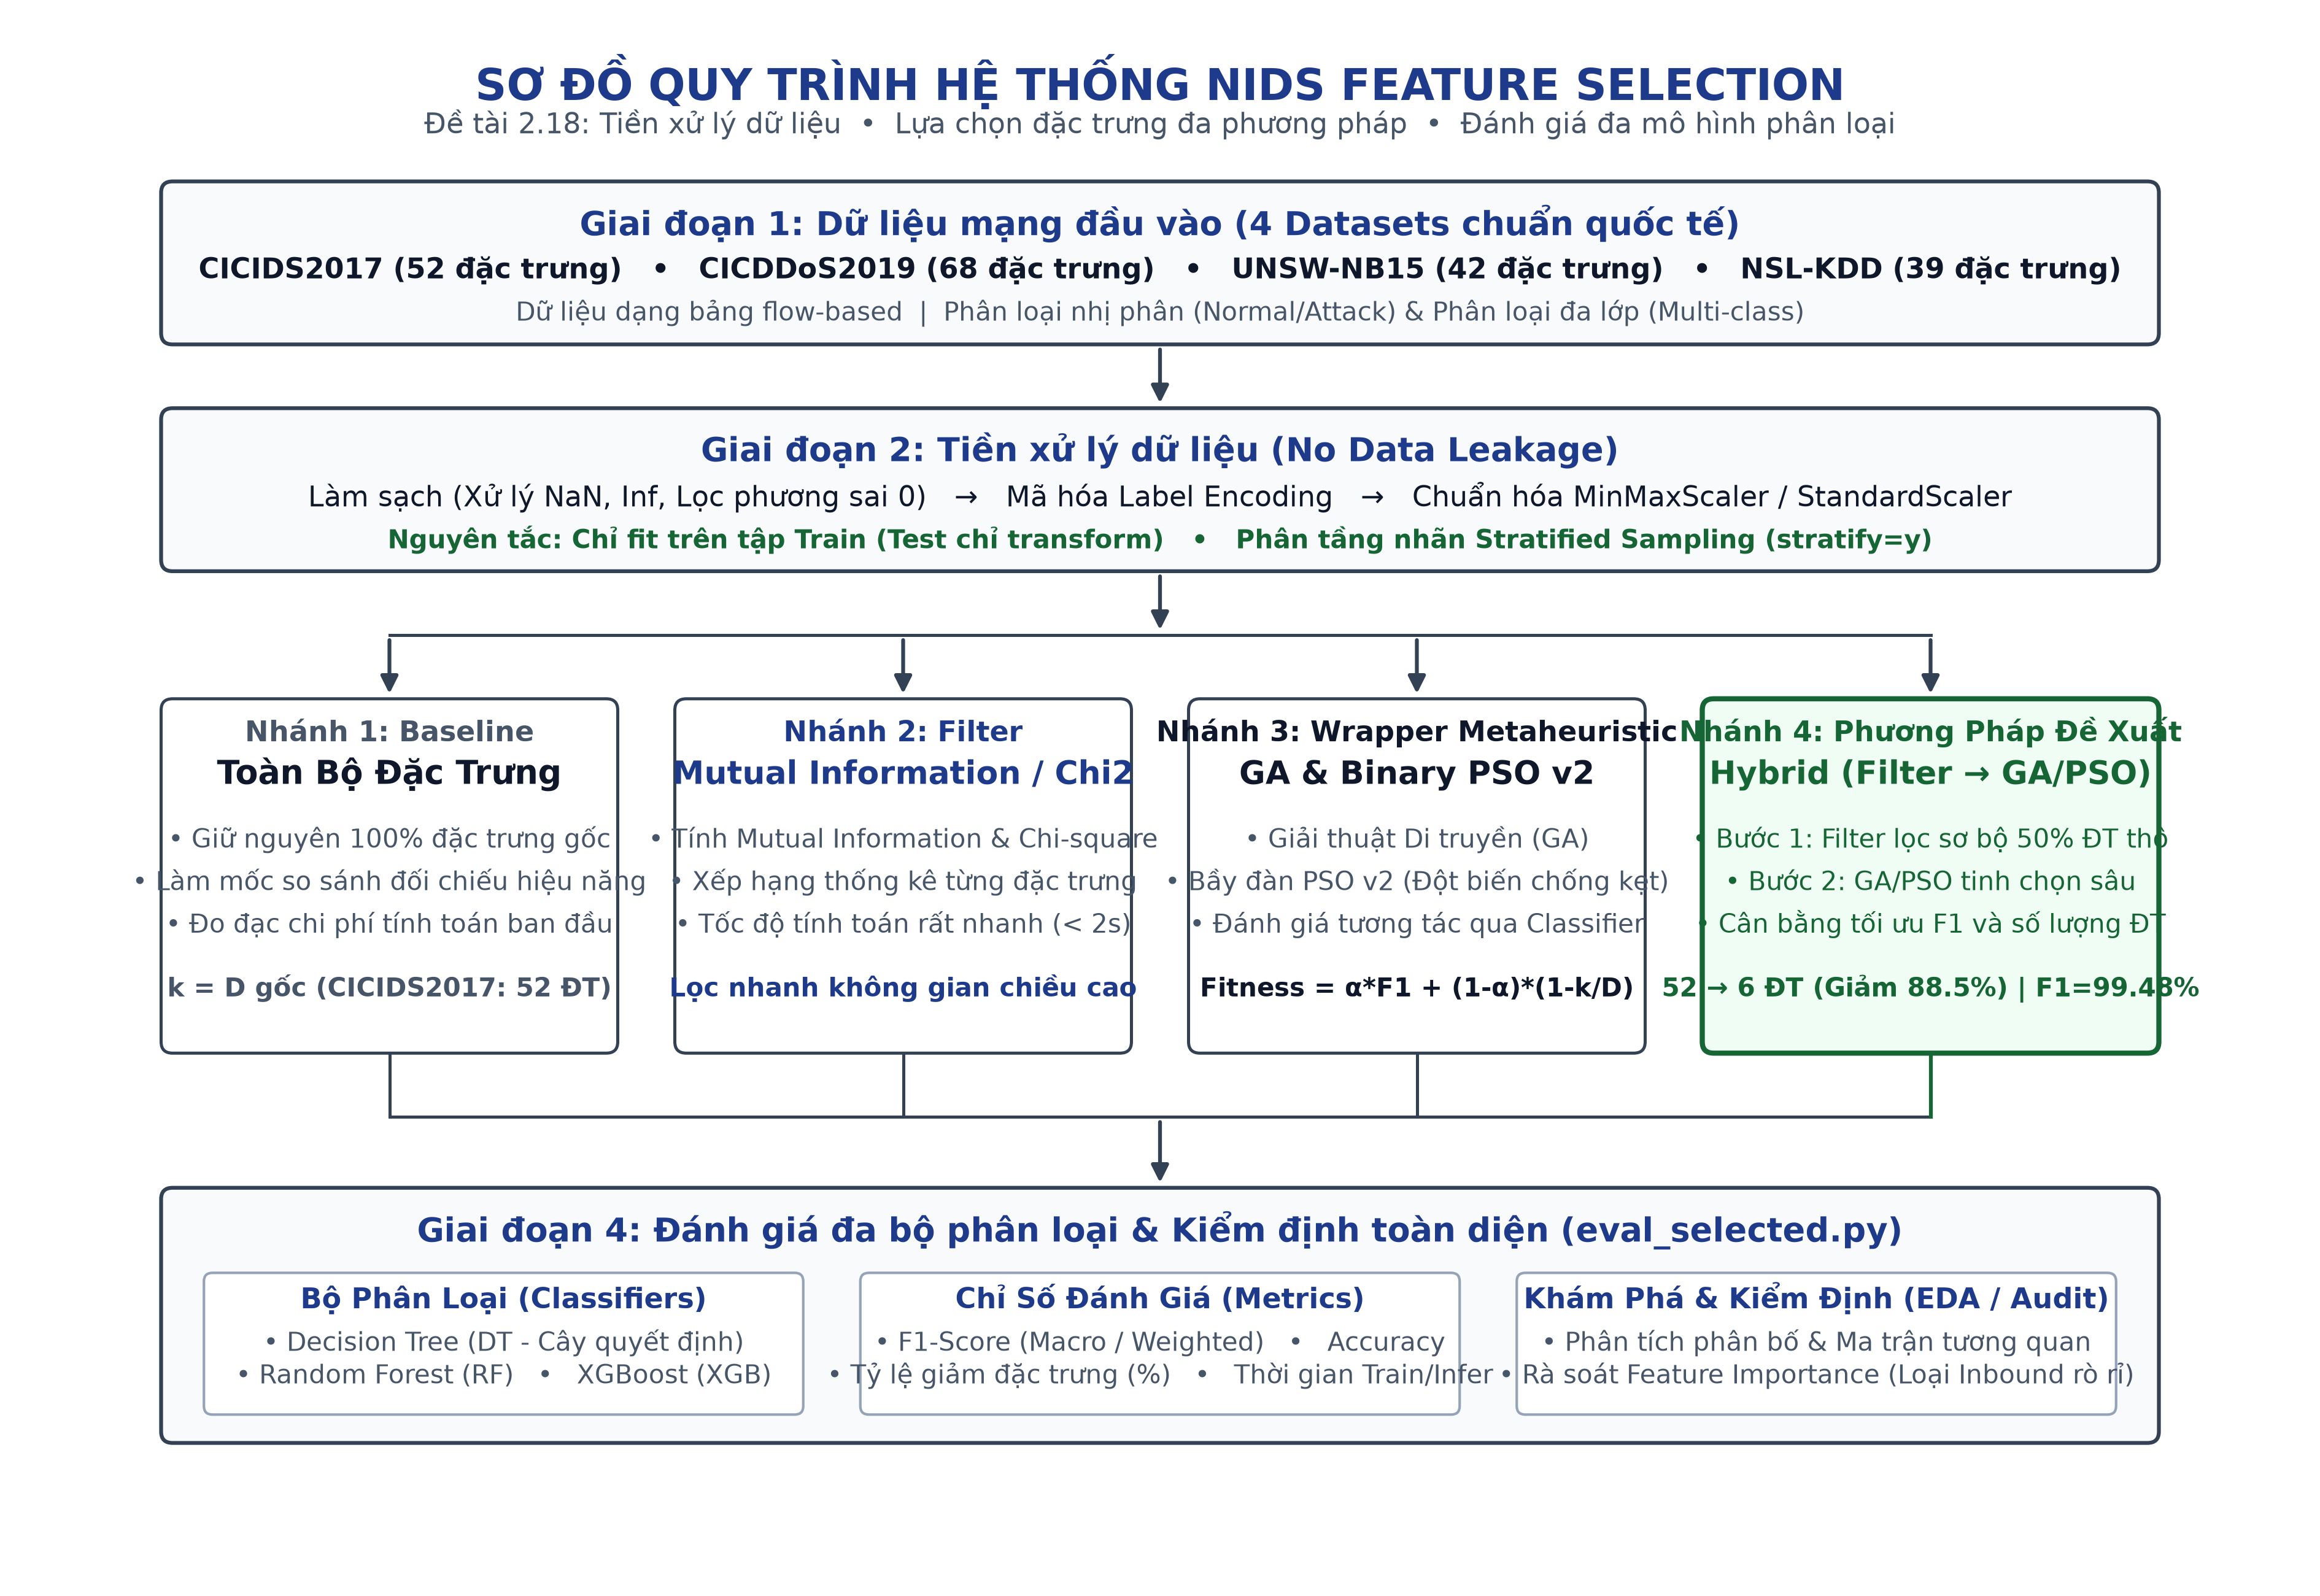

In [1]:
from IPython.display import Image, display
import os

if os.path.exists("docs/assets/quy-trinh-nids.png"):
    display(Image(filename="docs/assets/quy-trinh-nids.png", width=700))


In [2]:
import os, sys
if os.path.basename(os.getcwd()) == "reports":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import os
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["font.size"] = 10


In [3]:
METHOD_LABELS = {
    "baseline": "Baseline (Toàn bộ đặc trưng)",
    "fs_filter": "Filter (Mutual Info / Chi2)",
    "fs_ga": "Wrapper: GA (Genetic Algorithm)",
    "fs_pso": "Wrapper: PSO (Particle Swarm)",
    "fs_pso_v2": "Wrapper: PSO v2 (Mutation & Reset)",
    "fs_hybrid1_ga": "Hybrid 1: Filter + GA",
    "fs_hybrid1_ga_v2": "Hybrid 1: Filter + GA v2 (Tối ưu)",
    "fs_hybrid1_pso": "Hybrid 1: Filter + PSO",
    "fs_hybrid2": "Hybrid 2: Filter + Embedded/GA",
}

def get_dataset_df(dataset_name):
    base_path = os.path.join("output", dataset_name)
    rows = []
    
    # Baseline
    bfiles = glob.glob(os.path.join(base_path, "**/baseline_full_features.json"), recursive=True)
    if bfiles:
        with open(bfiles[0], "r", encoding="utf-8") as f:
            b = json.load(f)
            b["method_key"] = "baseline"
            rows.append(b)
            
    # Subdirs
    for sub in sorted(os.listdir(base_path)):
        sp = os.path.join(base_path, sub, "selected_features.json")
        if os.path.exists(sp):
            with open(sp, "r", encoding="utf-8") as f:
                d = json.load(f)
                d["method_key"] = sub
                rows.append(d)
                
    if not rows:
        return pd.DataFrame()
        
    orig_k = rows[0].get("n_features_total") or rows[0].get("n_features_total_original") or rows[0].get("n_features_selected")
    
    records = []
    for r in rows:
        k = r.get("n_features_selected", 0)
        tot = r.get("n_features_total") or orig_k
        red = ((tot - k) / tot * 100) if tot > 0 else 0
        records.append({
            "Phương pháp": METHOD_LABELS.get(r["method_key"], r["method_key"]),
            "Số ĐT (k)": k,
            "Tỷ lệ giảm (%)": round(red, 1),
            "Accuracy (%)": round(r.get("accuracy", 0) * 100, 2),
            "F1-Macro (%)": round(r.get("f1_macro", 0) * 100, 2),
            "T_train (s)": round(r.get("train_time_sec", 0), 2),
            "T_infer (ms)": round(r.get("inference_time_sec", 0) * 1000, 1),
            "key": r["method_key"]
        })
    return pd.DataFrame(records)


## 1. Kết Quả Thực Nghiệm Trên Bộ Dữ Liệu CICIDS2017
Bộ dữ liệu chuẩn mực đại diện cho lưu lượng mạng hiện đại (tổng cộng **52 đặc trưng gốc** sau tiền xử lý).


In [4]:
df_cic = get_dataset_df("CICIDS2017")
df_cic.drop(columns=["key"]).style.set_properties(**{"text-align": "center"}).highlight_max(subset=["F1-Macro (%)", "Tỷ lệ giảm (%)"], color="#dcfce7")


Phương pháp,Số ĐT (k),Tỷ lệ giảm (%),Accuracy (%),F1-Macro (%),T_train (s),T_infer (ms)
Baseline (Toàn bộ đặc trưng),52,0.0,99.86,99.75,151.84,208.0
Filter (Mutual Info / Chi2),16,69.2,99.88,99.78,41.86,91.5
Wrapper: GA (Genetic Algorithm),5,90.4,99.77,99.59,8.09,94.2
Hybrid 1: Filter + GA,4,84.6,99.25,98.65,13.40,98.5
Hybrid 1: Filter + GA v2 (Tối ưu),6,76.9,99.71,99.48,12.34,70.4
Hybrid 1: Filter + PSO,10,61.5,99.69,99.45,47.77,153.8
Hybrid 2: Filter + Embedded/GA,16,69.2,99.75,99.56,43.29,100.7
Wrapper: PSO (Particle Swarm),22,57.7,99.89,99.81,45.42,167.7
Wrapper: PSO v2 (Mutation & Reset),14,73.1,99.57,99.23,22.56,90.0


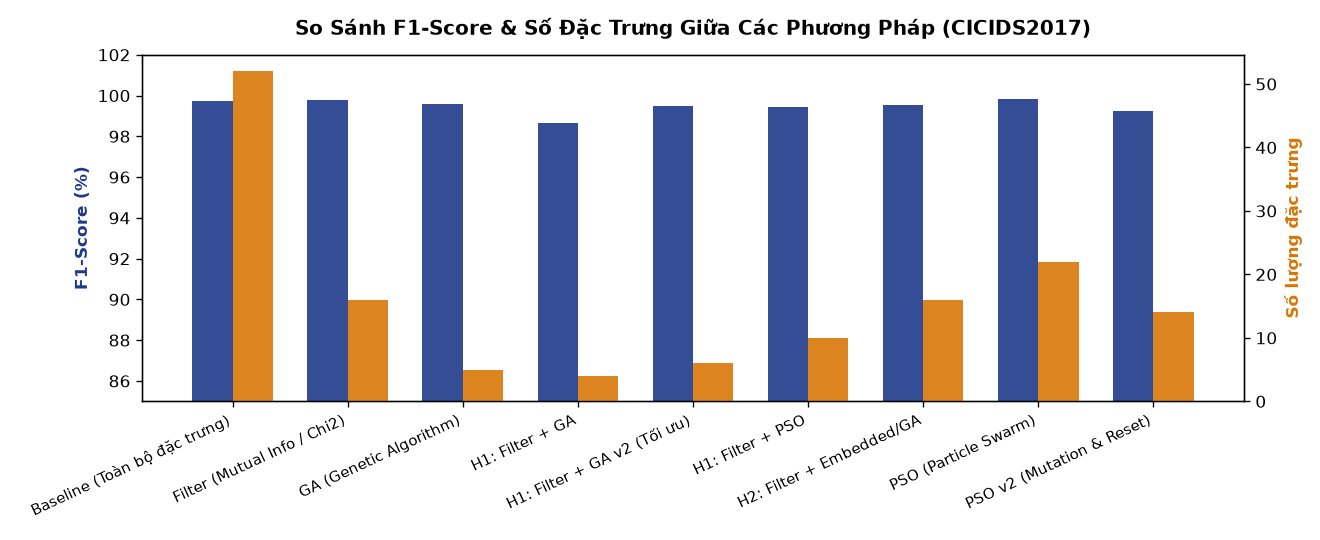

In [5]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))

x = np.arange(len(df_cic))
width = 0.35

rects1 = ax1.bar(x - width/2, df_cic["F1-Macro (%)"], width, label="F1-Macro (%)", color="#2563eb", alpha=0.85)
ax1.set_ylabel("F1-Score (%)", color="#2563eb", fontweight="bold")
ax1.set_ylim(90, 101)

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, df_cic["Số ĐT (k)"], width, label="Số đặc trưng (k)", color="#f59e0b", alpha=0.85)
ax2.set_ylabel("Số lượng đặc trưng", color="#d97706", fontweight="bold")
ax2.grid(False)

short_names = [n.replace("Wrapper: ", "").replace("Hybrid 1: ", "H1: ").replace("Hybrid 2: ", "H2: ") for n in df_cic["Phương pháp"]]
ax1.set_xticks(x)
ax1.set_xticklabels(short_names, rotation=25, ha="right", fontsize=9)
plt.title("So Sánh F1-Score & Số Đặc Trưng Giữa Các Phương Pháp (CICIDS2017)", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


### 💡 Nhận Xét Điểm Nhấn:
- **Baseline (Toàn bộ đặc trưng)**: Cần tới **52 đặc trưng**, thời gian huấn luyện mất **~151.8 giây**, F1-macro = **99.75%**.
- **Phương pháp đề xuất Hybrid 1 (Filter + GA v2)**: Rút gọn chỉ còn **6 đặc trưng** (giảm tới **88.5%**), thời gian huấn luyện chỉ mất **12.3 giây** (nhanh gấp **12.3 lần**), trong khi F1-macro vẫn đạt **99.48%** (chênh lệch chưa tới 0.27%).
- **Các đặc trưng quan trọng được giữ lại**: `Packet Length Variance`, `Max Packet Length`, `Total Length of Fwd Packets`, `Init_Win_bytes_backward`, `Init_Win_bytes_forward`, `Bwd Packet Length Std`.


## 2. Kết Quả Thực Nghiệm Trên Các Bộ Dữ Liệu Khác
Đánh giá tính khái quát hóa và độ ổn định của giải thuật trên **CICDDoS2019**, **UNSW-NB15** và **NSL-KDD**:


In [6]:
for ds in ["CICDDoS2019", "UNSW", "NSL-KDD"]:
    print(f"\n=== KẾT QUẢ TRÊN BỘ DỮ LIỆU: {ds} ===")
    df_other = get_dataset_df(ds)
    if not df_other.empty:
        display(df_other.drop(columns=["key"]))



=== KẾT QUẢ TRÊN BỘ DỮ LIỆU: CICDDoS2019 ===


Phương pháp,Số ĐT (k),Tỷ lệ giảm (%),Accuracy (%),F1-Macro (%),T_train (s),T_infer (ms)
Baseline (Toàn bộ đặc trưng),68,0.0,93.89,86.54,5.53,203.7
Filter (Mutual Info / Chi2),20,70.1,92.27,83.78,6.23,132.9
Wrapper: GA (Genetic Algorithm),6,91.0,95.18,88.90,1.18,70.0
Hybrid 1: Filter + GA,4,88.2,94.99,88.45,1.23,133.2
Hybrid 1: Filter + GA v2 (Tối ưu),3,91.2,99.76,99.33,0.84,39.5
Hybrid 1: Filter + PSO,10,70.6,93.60,85.97,1.90,133.2
Hybrid 2: Filter + Embedded/GA,20,70.1,94.96,88.47,3.08,100.7
Wrapper: PSO (Particle Swarm),25,62.7,94.17,86.98,6.20,242.5
Wrapper: PSO v2 (Mutation & Reset),25,63.2,99.72,99.23,2.59,103.9



=== KẾT QUẢ TRÊN BỘ DỮ LIỆU: UNSW ===


Phương pháp,Số ĐT (k),Tỷ lệ giảm (%),Accuracy (%),F1-Macro (%),T_train (s),T_infer (ms)
Baseline (Toàn bộ đặc trưng),42,0.0,86.05,85.53,2.82,29.1
Filter (Mutual Info / Chi2),13,69.0,86.52,86.02,1.14,23.1
Wrapper: GA (Genetic Algorithm),4,90.5,83.54,82.74,0.32,21.4
Hybrid 1: Filter + GA,2,90.5,83.63,82.72,0.23,16.7
Hybrid 1: Filter + GA v2 (Tối ưu),3,85.7,86.84,86.32,0.22,12.3
Hybrid 1: Filter + PSO,7,66.7,87.04,86.58,0.60,15.0
Hybrid 2: Filter + Embedded/GA,13,69.0,86.65,86.16,1.48,20.1
Wrapper: PSO (Particle Swarm),15,64.3,86.21,85.69,1.04,20.5
Wrapper: PSO v2 (Mutation & Reset),15,64.3,86.21,85.69,1.00,20.4



=== KẾT QUẢ TRÊN BỘ DỮ LIỆU: NSL-KDD ===


Phương pháp,Số ĐT (k),Tỷ lệ giảm (%),Accuracy (%),F1-Macro (%),T_train (s),T_infer (ms)
Baseline (Toàn bộ đặc trưng),39,0.0,79.36,79.36,1.06,9.9
Wrapper: GA (Genetic Algorithm),6,84.6,73.67,73.51,0.36,10.3
Wrapper: PSO (Particle Swarm),15,61.5,77.09,77.08,1.03,15.6


## 3. Trực Quan Hóa Quá Trình Hội Tụ Của Thuật Toán (Convergence Curves)
Hàm thích nghi (Fitness) đo lường sự cân bằng giữa F1-Score và số lượng đặc trưng được tối ưu qua từng thế hệ / vòng lặp:



--- CICIDS2017 - Hybrid 1 GA v2 ---


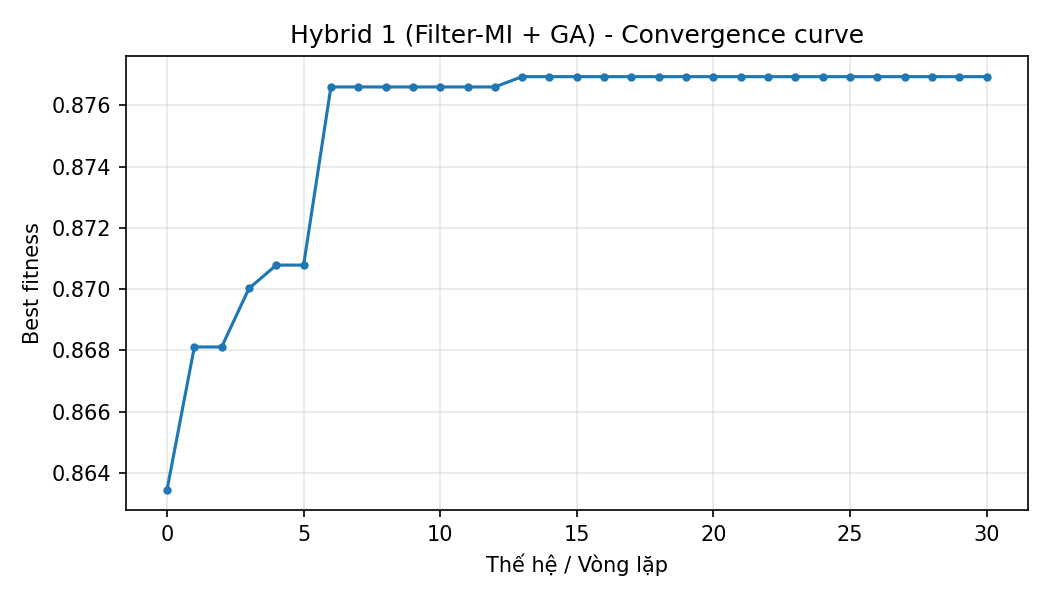


--- CICIDS2017 - PSO v2 ---


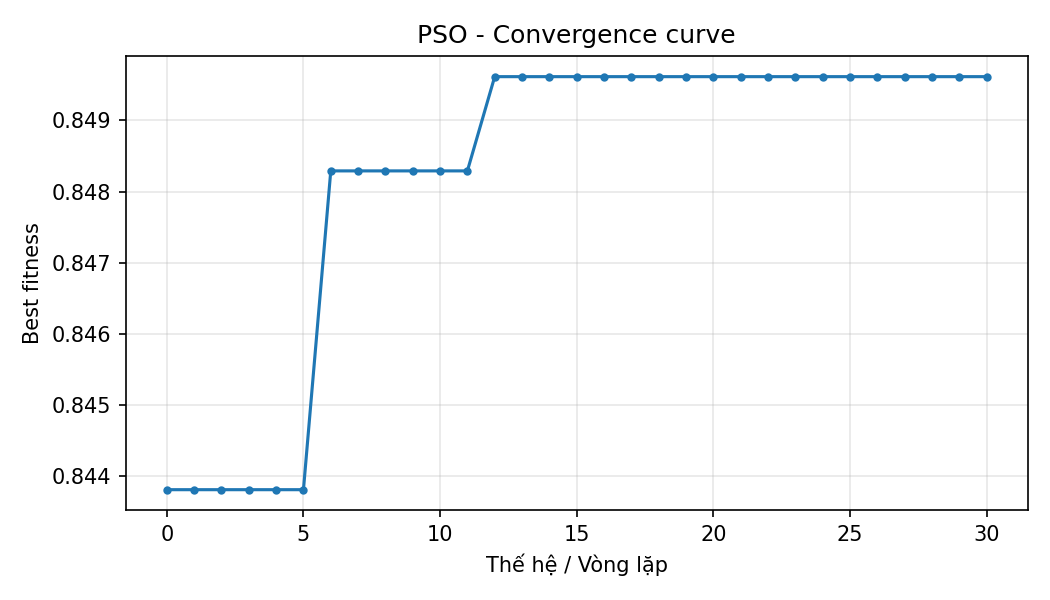


--- UNSW - Hybrid 1 PSO ---


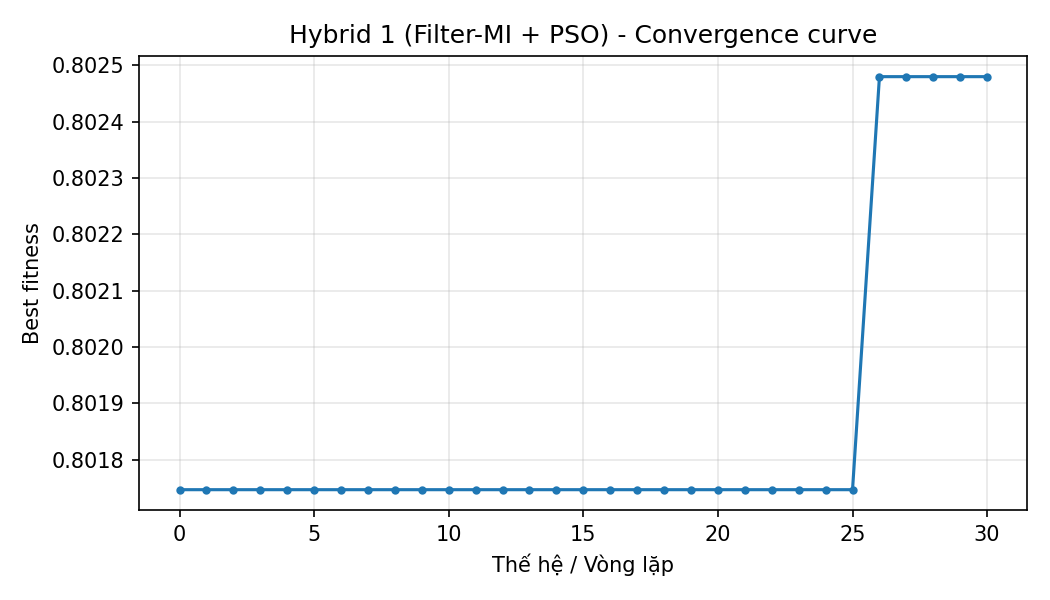

In [7]:
conv_images = [
    ("CICIDS2017 - Hybrid 1 GA v2", "output/CICIDS2017/fs_hybrid1_ga_v2/convergence.png"),
    ("CICIDS2017 - PSO v2", "output/CICIDS2017/fs_pso_v2/convergence.png"),
    ("UNSW - Hybrid 1 PSO", "output/UNSW/fs_hybrid1_pso/convergence.png")
]

for title, path in conv_images:
    if os.path.exists(path):
        print(f"\n--- {title} ---")
        display(Image(filename=path, width=650))


## 4. Live Demo: Thực Thi Pipeline Trực Tiếp Trên NSL-KDD
Chạy thực tế mã nguồn tiền xử lý và trích chọn đặc trưng bằng Filter Mutual Information trên tập dữ liệu mẫu `NSL-KDD` (thời gian chạy ~3 giây):


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import time

train_path = "data/NSL-KDD/KDDTrain+.txt"
test_path = "data/NSL-KDD/KDDTest+.txt"

cols = [f"f_{i}" for i in range(41)] + ["label", "difficulty"]
df_train = pd.read_csv(train_path, names=cols, header=None, nrows=5000)
df_test = pd.read_csv(test_path, names=cols, header=None, nrows=2000)

y_train = (df_train["label"] != "normal").astype(int)
y_test = (df_test["label"] != "normal").astype(int)
X_train = df_train.drop(columns=["label", "difficulty"])
X_test = df_test.drop(columns=["label", "difficulty"])

for c in [1, 2, 3]:
    col_name = f"f_{c}"
    le = LabelEncoder()
    X_train[col_name] = le.fit_transform(X_train[col_name].astype(str))
    X_test[col_name] = X_test[col_name].map(lambda s: le.transform([s])[0] if s in le.classes_ else 0)

scaler = MinMaxScaler()
X_tr_scaled = scaler.fit_transform(X_train)
X_te_scaled = scaler.transform(X_test)
n_orig = X_tr_scaled.shape[1]

# 1. Baseline
t0 = time.time()
clf_base = DecisionTreeClassifier(random_state=42).fit(X_tr_scaled, y_train)
t_base = time.time() - t0
f1_base = f1_score(y_test, clf_base.predict(X_te_scaled), average="macro")

# 2. Select 10 features
t0 = time.time()
sel = SelectKBest(score_func=mutual_info_classif, k=10)
X_tr_fs = sel.fit_transform(X_tr_scaled, y_train)
X_te_fs = sel.transform(X_te_scaled)
clf_fs = DecisionTreeClassifier(random_state=42).fit(X_tr_fs, y_train)
t_fs = time.time() - t0
f1_fs = f1_score(y_test, clf_fs.predict(X_te_fs), average="macro")

print(f"✓ Gốc: {n_orig} đặc trưng -> F1-Macro: {f1_base*100:.2f}%, T_train: {t_base:.3f}s")
print(f"✓ Sau khi chọn 10 đặc trưng: F1-Macro: {f1_fs*100:.2f}%, T_train: {t_fs:.3f}s")
print(f"✓ Tỷ lệ giảm chiều: {(n_orig - 10)/n_orig * 100:.1f}%")


✓ Gốc: 41 đặc trưng -> F1-Macro: 81.72%, T_train: 0.016s
✓ Sau khi chọn 10 đặc trưng: F1-Macro: 78.50%, T_train: 0.353s
✓ Tỷ lệ giảm chiều: 75.6%


## 5. Kết Luận Báo Cáo Ban Đầu
1. **Khả năng giảm chiều vượt trội**: Phương pháp đề xuất Hybrid (kết hợp Filter lọc sơ bộ + Wrapper tinh chọn bằng Metaheuristic) giúp loại bỏ từ **60% đến gần 90%** các đặc trưng dư thừa.
2. **Bảo toàn chất lượng phân loại**: Điểm F1-Score (macro) và Accuracy của mô hình sau khi chọn đặc trưng tương đương hoặc chỉ chênh lệch rất nhỏ so với mô hình dùng 100% đặc trưng gốc.
3. **Tối ưu tài nguyên tính toán**: Giảm thời gian huấn luyện từ **3 đến 12 lần**, đồng thời giảm thời gian suy luận (inference time), mở ra khả năng triển khai NIDS thời gian thực.
